In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

In [9]:
from pathlib import Path
import pandas as pd

dir_path = Path(r'S:\Stratosphere\2026\strategy_economics\Hist')

histories = {}

for file in dir_path.glob('* Hist.csv'):

    ticker = file.stem.removesuffix(' Hist')

    df = pd.read_csv(file)
    df.set_index('Date',inplace=True)

    histories[ticker] = df


    print(f"Loaded {ticker}")

Loaded A
Loaded AAL
Loaded AAPL
Loaded ABT
Loaded ACGL
Loaded ACN
Loaded ADBE
Loaded ADI
Loaded ADM
Loaded ADP
Loaded ADSK
Loaded AEE
Loaded AEP
Loaded AES
Loaded AFL
Loaded AIG
Loaded AIZ
Loaded AJG
Loaded AKAM
Loaded ALB
Loaded ALGN
Loaded ALL
Loaded AMAT
Loaded AMD
Loaded AME
Loaded AMGN
Loaded AMP
Loaded AMT
Loaded AMZN
Loaded ANSS
Loaded AON
Loaded AOS
Loaded APA
Loaded APD
Loaded APH
Loaded ARE
Loaded ATO
Loaded AVB
Loaded AVGO
Loaded AVY
Loaded AWK
Loaded AXON
Loaded AXP
Loaded AZO
Loaded BA
Loaded BAC
Loaded BALL
Loaded BAX
Loaded BBWI
Loaded BBY
Loaded BDX
Loaded BEN
Loaded BG
Loaded BIIB
Loaded BIO
Loaded BK
Loaded BKNG
Loaded BKR
Loaded BLDR
Loaded BLK
Loaded BMY
Loaded BR
Loaded BRO
Loaded BSX
Loaded BWA
Loaded BX
Loaded BXP
Loaded C
Loaded CAG
Loaded CAH
Loaded CAT
Loaded CB
Loaded CBRE
Loaded CCI
Loaded CCL
Loaded CDNS
Loaded CE
Loaded CF
Loaded CHD
Loaded CHRW
Loaded CI
Loaded CINF
Loaded CL
Loaded CLX
Loaded CMA
Loaded CMCSA
Loaded CME
Loaded CMG
Loaded CMI
Loaded CMS
L

In [10]:
histories['AAPL']

,Close AAPL
Date,
2010-01-04,6.470743
2010-01-05,6.481928
2010-01-06,6.378824
2010-01-07,6.367032
2010-01-08,6.409363
...,...
2024-04-01,170.029999
2024-04-02,168.839996
2024-04-03,169.649994


In [28]:

from pathlib import Path
import pandas as pd
import numpy as np
import statsmodels.api as sm


# ============================================================
# CONFIG
# ============================================================

PARENT_DIR = Path(r"S:\Stratosphere\2026\strategy_economics")

HIST_DIR = PARENT_DIR / "Hist"
FACTOR_DIR = PARENT_DIR / "Factors"

START_DATE = "2011-01-01"
END_DATE = "2017-01-01"       # None for all available data

PRICE_COL = "Close"           # Asset column convention: "Close {ticker}"

# Regression frequency
REGRESSION_FREQ = "monthly"

# Regression settings
USE_HAC = True
HAC_LAGS = 3                 # 3 monthly lags
MIN_OBS = 36                 # Minimum number of monthly observations

# Factor settings:
# frequency = native data frequency (metadata)
# periods = number of REGRESSION-frequency periods
#            after resampling (1 = one month)

FACTOR_CFG = {
    "CAPM": {
        "transform": "pct_change",
        "frequency": "daily",
        "periods": 1,
    },
    # "CCDebt": {
    #     "transform": "pct_change",
    #     "frequency": "weekly",
    #     "periods": 1,
    # },
    # "ConstructionSpending": {
    #     "transform": "pct_change",
    #     "frequency": "monthly",
    #     "periods": 1,
    # },
    # # "EmploymentRate": {
    # #     "transform": "diff",
    # #     "frequency": "monthly",
    # #     "periods": 1,
    # # },
    # "OilPrices": {
    #     "transform": "pct_change",
    #     "frequency": "monthly",
    #     "periods": 1,
    # },
}


# ============================================================
# LOAD ASSET HISTORIES
# ============================================================

def load_histories(hist_dir):

    histories = {}

    for file in hist_dir.glob("* Hist.csv"):

        ticker = file.stem.removesuffix(" Hist")

        df = pd.read_csv(
            file,
            parse_dates=["Date"],
            index_col="Date",
        ).sort_index()

        df.columns = df.columns.str.strip()
        df = df[~df.index.duplicated(keep="last")]

        histories[ticker] = df

    print(f"Loaded {len(histories)} asset histories")

    return histories


# ============================================================
# FACTOR TRANSFORMATIONS
# ============================================================

def transform_factor(x, transform="level", periods=1):

    if transform == "level":
        return x

    elif transform == "diff":
        return x.diff(periods=periods)

    elif transform == "pct_change":
        return x.pct_change(
            periods=periods,
            fill_method=None
        )

    else:
        raise ValueError(
            f"Unknown transformation: {transform}"
        )


# ============================================================
# MONTHLY ALIGNMENT
# ============================================================

def to_monthly_levels(x):

    """
    Convert raw levels to monthly frequency.

    Daily/weekly data:
        Take last available observation in each month.

    Monthly data:
        Treat dates as labels for the represented month.

    Missing months remain NaN rather than being
    automatically forward-filled.
    """

    x = x.sort_index()

    # Convert all observation dates into month-end labels
    x.index = (
        x.index.to_period("M")
        .to_timestamp("M")
    )

    # Last observed value within each month
    x = x.groupby(level=0).last()

    # Regular monthly calendar
    x = x.resample("ME").last()

    return x


# ============================================================
# LOAD FACTORS
# ============================================================

def load_factors(
    cfg,
    factor_dir,
    master_dates,
    regression_freq="monthly"
):

    if regression_freq != "monthly":
        raise ValueError(
            "Currently only monthly regression is supported."
        )

    factors = pd.DataFrame()

    for name, settings in cfg.items():

        file = factor_dir / f"{name}.csv"

        df = pd.read_csv(
            file,
            parse_dates=["Date"],
            index_col="Date",
        ).sort_index()

        df.columns = df.columns.str.strip()
        df = df[~df.index.duplicated(keep="last")]

        col = settings.get("column", df.columns[0])

        x = pd.to_numeric(
            df[col],
            errors="coerce"
        ).dropna()

        transform = settings.get("transform", "level")
        periods = settings.get("periods", 1)
        frequency = settings.get("frequency", "daily")

        if frequency not in ["daily", "weekly", "monthly"]:
            raise ValueError(
                f"Unknown frequency for {name}: {frequency}"
            )

        # 1. Convert raw factor levels to monthly frequency
        x = to_monthly_levels(x)

        # 2. Apply transformation at monthly frequency
        x = transform_factor(
            x,
            transform=transform,
            periods=periods
        )

        # 3. Store in factor matrix
        factors[name] = x

        print(
            f"Loaded {name}: "
            f"{transform}({periods}), "
            f"native frequency={frequency}"
        )

    # Master monthly index from asset trading dates
    master_months = (
        pd.DatetimeIndex(master_dates)
        .to_period("M")
        .to_timestamp("M")
        .unique()
        .sort_values()
    )

    factors = factors.reindex(master_months)

    return factors


# ============================================================
# RUN FACTOR REGRESSIONS
# ============================================================

def run_factor_regressions(
    histories,
    factors,
    start_date=None,
    end_date=None,
    price_col_prefix="Close",
    use_hac=True,
    hac_lags=3,
    min_obs=36,
):

    results = {}
    fitted = {}
    regression_data = {}

    for ticker, df in histories.items():

        price_col = f"{price_col_prefix} {ticker}"

        if price_col not in df.columns:
            print(
                f"Skipping {ticker}: missing {price_col}"
            )
            continue

        # ---------------------------------------------
        # Monthly asset returns
        # ---------------------------------------------

        price = pd.to_numeric(
            df[price_col],
            errors="coerce"
        ).sort_index()

        # Last trading-day price in each month
        monthly_price = price.resample("ME").last()

        # Non-overlapping monthly returns
        y = monthly_price.pct_change(
            fill_method=None
        ).rename("return")

        # ---------------------------------------------
        # Align factors and dependent variable
        # ---------------------------------------------

        data = factors.join(y, how="inner")

        # ---------------------------------------------
        # Apply training window AFTER transformations
        # ---------------------------------------------

        if start_date is not None:
            data = data.loc[
                data.index >= pd.Timestamp(start_date)
            ]

        if end_date is not None:
            data = data.loc[
                data.index <= pd.Timestamp(end_date)
            ]

        # Remove missing or infinite observations
        data = data.replace(
            [np.inf, -np.inf],
            np.nan
        ).dropna()

        n_factors = len(factors.columns)

        if len(data) < max(min_obs, n_factors + 2):
            print(
                f"Skipping {ticker}: "
                f"only {len(data)} valid observations"
            )
            continue

        # ---------------------------------------------
        # OLS
        # ---------------------------------------------

        X_reg = sm.add_constant(
            data[factors.columns],
            has_constant="add"
        )

        y_reg = data["return"]

        if use_hac:

            model = sm.OLS(
                y_reg,
                X_reg
            ).fit(
                cov_type="HAC",
                cov_kwds={"maxlags": hac_lags}
            )

        else:

            model = sm.OLS(
                y_reg,
                X_reg
            ).fit()

        # ---------------------------------------------
        # Store outputs
        # ---------------------------------------------

        results[ticker] = model
        regression_data[ticker] = data

        fitted[ticker] = pd.DataFrame({
            "actual": y_reg,
            "fitted": model.fittedvalues,
            "residual": model.resid,
        })

    print(
        f"Estimated {len(results)} "
        f"monthly factor regressions"
    )

    return results, fitted, regression_data


# ============================================================
# EXECUTION
# ============================================================

# 1. Load asset histories
histories = load_histories(HIST_DIR)

if not histories:
    raise ValueError("No asset histories found.")

# 2. Construct master date index
master_dates = pd.DatetimeIndex(
    sorted(
        set().union(*[
            df.index for df in histories.values()
        ])
    )
)

# 3. Load and transform factors
factors = load_factors(
    cfg=FACTOR_CFG,
    factor_dir=FACTOR_DIR,
    master_dates=master_dates,
    regression_freq=REGRESSION_FREQ,
)

# 4. Estimate monthly regressions
results, fitted, regression_data = run_factor_regressions(
    histories=histories,
    factors=factors,
    start_date=START_DATE,
    end_date=END_DATE,
    price_col_prefix=PRICE_COL,
    use_hac=USE_HAC,
    hac_lags=HAC_LAGS,
    min_obs=MIN_OBS,
)


# ============================================================
# RESULTS
# ============================================================

# Coefficient matrix
coefficients = pd.DataFrame({
    ticker: model.params
    for ticker, model in results.items()
}).T

# R-squared
r_squared = pd.Series({
    ticker: model.rsquared
    for ticker, model in results.items()
}, name="R_squared")

# Adjusted R-squared
adj_r_squared = pd.Series({
    ticker: model.rsquared_adj
    for ticker, model in results.items()
}, name="Adj_R_squared")

# Sample sizes
n_obs = pd.Series({
    ticker: int(model.nobs)
    for ticker, model in results.items()
}, name="N_obs")

# Final summary
factor_summary = coefficients.join([
    r_squared,
    adj_r_squared,
    n_obs,
])

display(factor_summary)

factor_summary.to_csv('factor_exposures_1.csv',index=True)


# ============================================================
# OPTIONAL DIAGNOSTICS
# ============================================================

# Inspect monthly factor matrix
display(factors.describe())

# Individual regression
# print(results["AAPL"].summary())

# Actual vs fitted monthly returns
# fitted["AAPL"].plot(y=["actual", "fitted"])

#Factor correlation matrix
display(factors.corr())

#Coefficient p-values
p_values = pd.DataFrame({
    ticker: model.pvalues
    for ticker, model in results.items()
}).T
display(p_values)


Loaded 434 asset histories
Loaded CAPM: pct_change(1), native frequency=daily
Estimated 434 monthly factor regressions


,const,CAPM,R_squared,Adj_R_squared,N_obs
A,-0.006068,1.486064,0.467290,0.459680,72
AAL,0.020949,1.004847,0.052169,0.038629,72
AAPL,0.006435,0.998472,0.211661,0.200399,72
ABT,-0.000045,1.039807,0.432631,0.424526,72
ACGL,0.010123,0.561875,0.205947,0.194603,72
...,...,...,...,...,...
XEL,0.010770,0.085508,0.004741,-0.009477,72
XOM,-0.002610,0.863296,0.419795,0.411507,72
YUM,0.003757,0.755095,0.188964,0.177378,72
ZBH,0.000767,1.044099,0.337200,0.327732,72


,CAPM
count,166.000000
mean,0.010511
std,0.042417
min,-0.124871
25%,-0.014485
50%,0.015722
75%,0.036747
max,0.126983


,CAPM
CAPM,1.0


,const,CAPM
A,0.271433,4.437929e-13
AAL,0.232763,8.127285e-02
AAPL,0.461052,1.390444e-04
ABT,0.993675,7.767828e-06
ACGL,0.015272,7.338236e-08
...,...,...
XEL,0.009038,5.140864e-01
XOM,0.483368,1.193966e-12
YUM,0.412204,6.639759e-04
ZBH,0.876363,1.578867e-07


Fama-MacBeth complete: 72 months, 434 eligible assets, 1 factors


,Monthly_Premium,Annual_Premium,SE_Monthly,t_stat,p_value,N_months
const,0.014148,0.169772,0.003372,4.195816,0.000027,72
CAPM,-0.000200,-0.002395,0.004981,-0.040067,0.968040,72



Average cross-sectional R-squared: 0.08825398135273092
Average number of assets per month: 434.0


,const,CAPM
count,72.000000,72.000000
mean,0.014148,-0.000200
std,0.029214,0.043929
min,-0.050419,-0.107150
25%,-0.005768,-0.021758
50%,0.016381,-0.001876
75%,0.034527,0.026852
max,0.083131,0.131929


,CAPM
CAPM,1.0



Market diagnostics:
Average market return: 0.010286868270588306
Average F-M market premium: -0.0001995722284050893
Market return / F-M lambda correlation: 0.7507268994211275


<Axes: title={'center': 'Cumulative Fama-MacBeth Factor Premia'}>

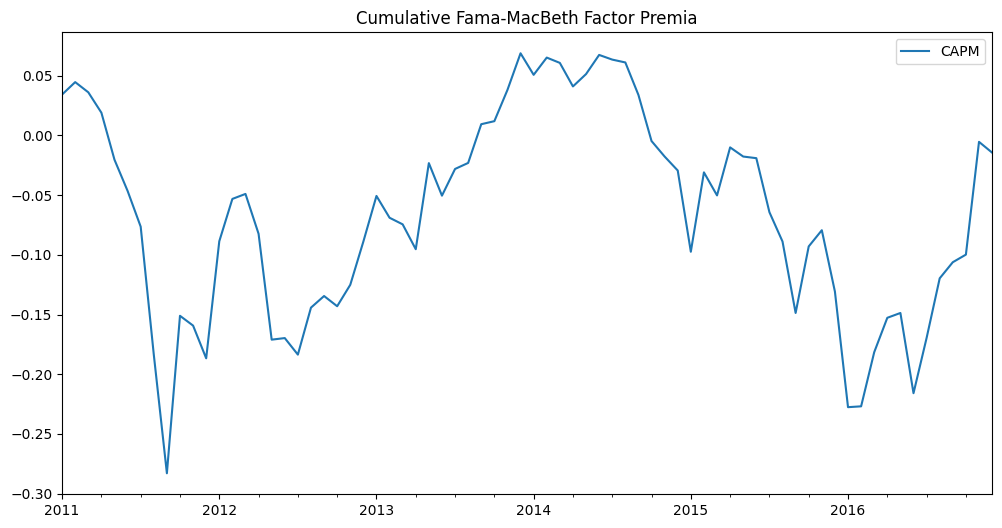

In [30]:

# ============================================================
# FAMA-MACBETH CROSS-SECTIONAL REGRESSIONS
# ============================================================

def run_fama_macbeth(
    regression_data,
    coefficients,
    factor_names,
    use_hac=True,
    hac_lags=3,
    min_assets=None,
    balanced_panel=False,
):

    factor_names = list(factor_names)

    # --------------------------------------------------------
    # 1. Construct monthly returns from first-pass samples
    # --------------------------------------------------------

    monthly_returns = pd.concat(
        {
            ticker: data["return"]
            for ticker, data in regression_data.items()
            if ticker in coefficients.index
        },
        axis=1
    ).sort_index()

    # Optional: require every asset to have the same dates
    if balanced_panel:
        monthly_returns = monthly_returns.dropna(axis=0)

    # --------------------------------------------------------
    # 2. Extract first-pass factor loadings
    # --------------------------------------------------------

    betas = coefficients[factor_names].copy()

    betas = betas.replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    common_assets = betas.index.intersection(
        monthly_returns.columns
    )

    betas = betas.loc[common_assets]
    monthly_returns = monthly_returns[common_assets]

    if min_assets is None:
        min_assets = max(len(factor_names) + 2, 10)

    # --------------------------------------------------------
    # 3. Cross-sectional regressions, one per month
    # --------------------------------------------------------

    lambda_series = {}
    cross_sectional_r2 = {}
    cross_sectional_n = {}

    for date, row in monthly_returns.iterrows():

        valid_assets = row.dropna().index

        if len(valid_assets) < min_assets:
            continue

        X = sm.add_constant(
            betas.loc[valid_assets],
            has_constant="add"
        )

        y = row.loc[valid_assets]

        # Skip rank-deficient cross sections
        if np.linalg.matrix_rank(X.to_numpy()) < X.shape[1]:
            continue

        model = sm.OLS(y, X).fit()

        lambda_series[date] = model.params
        cross_sectional_r2[date] = model.rsquared
        cross_sectional_n[date] = int(model.nobs)

    if not lambda_series:
        raise ValueError(
            "No valid cross-sectional regressions."
        )

    # Rows = months; columns = factor risk premia
    lambdas = pd.DataFrame.from_dict(
        lambda_series,
        orient="index"
    ).sort_index()

    # --------------------------------------------------------
    # 4. Mean risk premia and statistical significance
    # --------------------------------------------------------

    summary_rows = {}

    for factor in lambdas.columns:

        series = lambdas[factor].dropna()

        X_mean = np.ones((len(series), 1))

        if use_hac:
            mean_model = sm.OLS(
                series.to_numpy(),
                X_mean
            ).fit(
                cov_type="HAC",
                cov_kwds={
                    "maxlags": min(hac_lags, len(series) - 1)
                }
            )
        else:
            mean_model = sm.OLS(
                series.to_numpy(),
                X_mean
            ).fit()

        summary_rows[factor] = {
            "Monthly_Premium": mean_model.params[0],
            "Annual_Premium": mean_model.params[0] * 12,
            "SE_Monthly": mean_model.bse[0],
            "t_stat": mean_model.tvalues[0],
            "p_value": mean_model.pvalues[0],
            "N_months": len(series),
        }

    premium_summary = pd.DataFrame.from_dict(
        summary_rows,
        orient="index"
    )

    # --------------------------------------------------------
    # 5. Diagnostics
    # --------------------------------------------------------

    diagnostics = pd.DataFrame({
        "R_squared": pd.Series(cross_sectional_r2),
        "N_assets": pd.Series(cross_sectional_n),
    }).sort_index()

    print(
        f"Fama-MacBeth complete: "
        f"{len(lambdas)} months, "
        f"{len(common_assets)} eligible assets, "
        f"{len(factor_names)} factors"
    )

    return premium_summary, lambdas, diagnostics


# ============================================================
# EXECUTION
# ============================================================

premium_summary, lambdas, cs_diagnostics = run_fama_macbeth(
    regression_data=regression_data,
    coefficients=coefficients,
    factor_names=list(FACTOR_CFG.keys()),
    use_hac=USE_HAC,
    hac_lags=HAC_LAGS,
    min_assets=10,
    balanced_panel=False,
)


# ============================================================
# RESULTS
# ============================================================

display(premium_summary)

print(
    "\nAverage cross-sectional R-squared:",
    cs_diagnostics["R_squared"].mean()
)

print(
    "Average number of assets per month:",
    cs_diagnostics["N_assets"].mean()
)


# ============================================================
# OPTIONAL DIAGNOSTICS
# ============================================================

# Monthly estimated factor premia
display(lambdas.describe())

# Cross-sectional beta correlations
display(
    coefficients[list(FACTOR_CFG.keys())].corr()
)

# Compare realized market returns and F-M market premium
comparison = pd.DataFrame({
    "Market_Return": factors["CAPM"],
    "FM_CAPM": lambdas["CAPM"],
}).dropna()

print("\nMarket diagnostics:")
print("Average market return:", comparison["Market_Return"].mean())
print("Average F-M market premium:", comparison["FM_CAPM"].mean())
print(
    "Market return / F-M lambda correlation:",
    comparison["Market_Return"].corr(
        comparison["FM_CAPM"]
    )
)

# Plot cumulative monthly factor premia
lambdas[list(FACTOR_CFG.keys())].cumsum().plot(
    figsize=(12, 6),
    title="Cumulative Fama-MacBeth Factor Premia"
)
